# SmartWaste AI: data analysis

TrashNet (6 classes) after perceptual-hash deduplication, split once into train/val/test 70/15/15 (`seed=42`)
by `src/prepare_split.py`. Figures are saved as `reports/data_*.png`.

Needs `data/raw/` (run `python src/prepare_split.py`).

In [1]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "splits" / "splits.csv").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from src.dataset import CLASSES, read_split

REPORTS = ROOT / "reports"
SEED = 42


def show(ax, path, title=None):
    with Image.open(path) as img:
        ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=8)

## 1. Class distribution
Raw images, duplicates removed, and the fixed split. `trash` is the smallest class by far, which is why the main metric is macro F1 (every class counts the same).

,raw,duplicates_removed,kept,train,val,test
class,,,,,,
cardboard,403,2,401,281,60,60
glass,501,4,497,348,74,75
metal,410,4,406,284,61,61
paper,594,23,571,399,86,86
plastic,482,2,480,336,72,72
trash,137,0,137,96,21,20


total: {'raw': 2527, 'duplicates_removed': 35, 'kept': 2492, 'train': 1744, 'val': 374, 'test': 374}


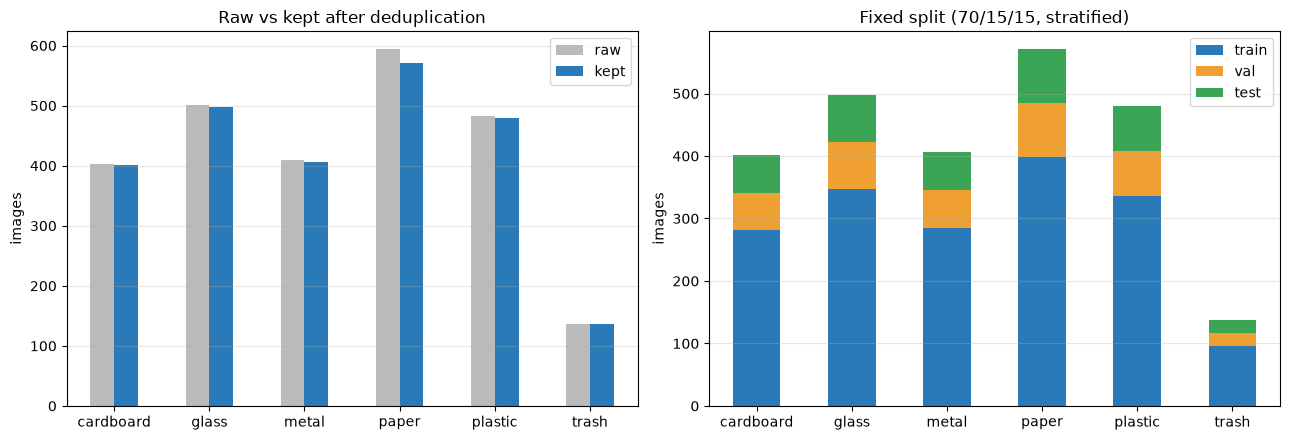

In [2]:
counts = pd.read_csv(REPORTS / "class_counts.csv").set_index("class")
display(counts)
print("total:", counts.sum().to_dict())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
counts[["raw", "kept"]].plot.bar(ax=ax1, rot=0, color=["#bbbbbb", "#2a7ab9"])
ax1.set(title="Raw vs kept after deduplication", ylabel="images", xlabel="")
counts[["train", "val", "test"]].plot.bar(ax=ax2, rot=0, stacked=True, color=["#2a7ab9", "#f0a030", "#3aa655"])
ax2.set(title="Fixed split (70/15/15, stratified)", ylabel="images", xlabel="")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(REPORTS / "data_class_distribution.png", dpi=120)
plt.show()

## 2. Samples per class
4 random train images per class (seed 42).

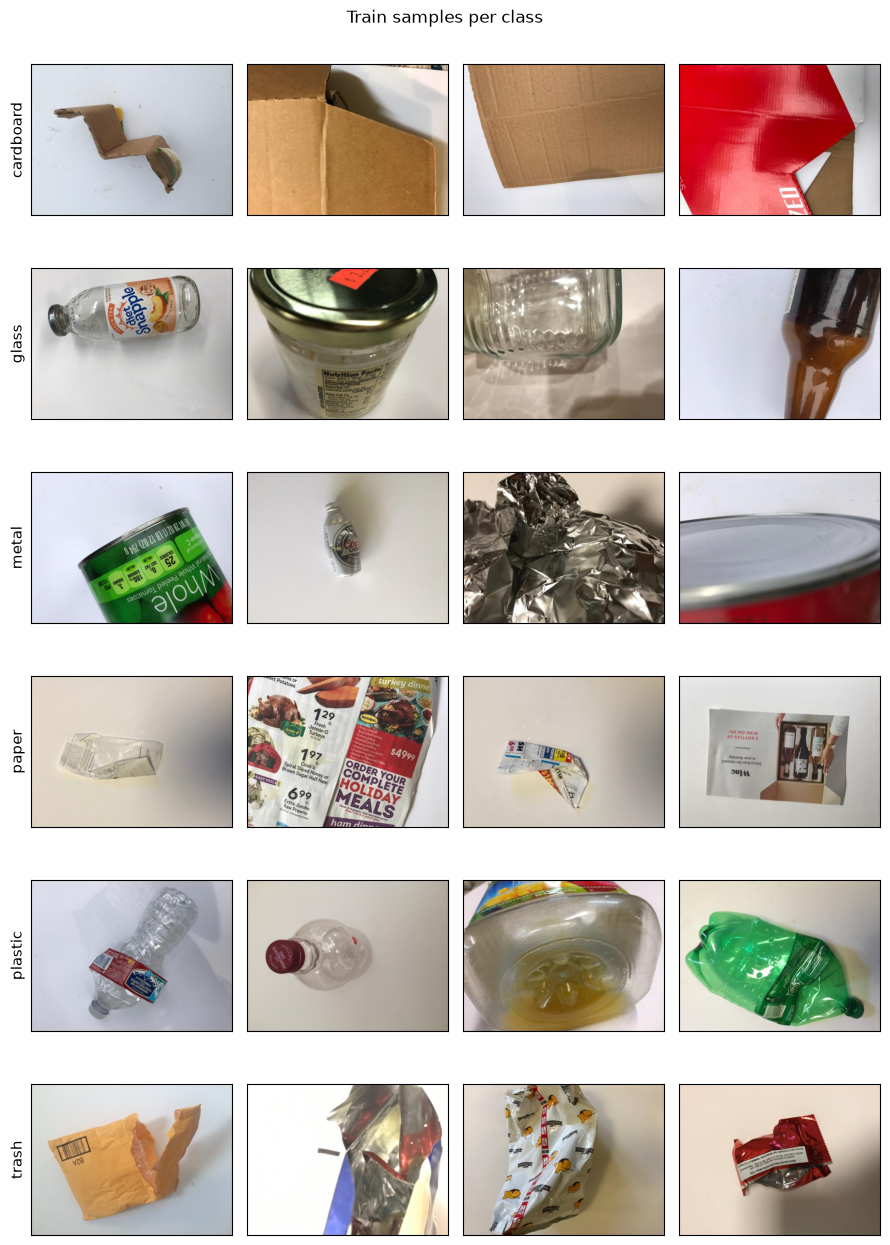

In [3]:
train = read_split("train")
rng = random.Random(SEED)
by_class = {c: [p for p, label in train if label == i] for i, c in enumerate(CLASSES)}

fig, axes = plt.subplots(len(CLASSES), 4, figsize=(9, 13))
for row, cls in enumerate(CLASSES):
    for col, path in enumerate(rng.sample(by_class[cls], 4)):
        show(axes[row, col], path)
    axes[row, 0].set_ylabel(cls, fontsize=11)
fig.suptitle("Train samples per class")
fig.tight_layout()
fig.savefig(REPORTS / "data_samples.png", dpi=100)
plt.show()

## 3. Duplicates
Pairs found by a 256-bit perceptual hash (distance ≤ 48). One image of each same-label pair is kept; when the same photo appears under two labels, both are dropped (`dropped_mixed_labels`).

action,dropped,dropped_mixed_labels,kept,All
label,,,,
cardboard,2,0,2,4
glass,1,3,1,5
metal,3,1,3,7
paper,23,0,23,46
plastic,0,2,0,2
All,29,6,29,64


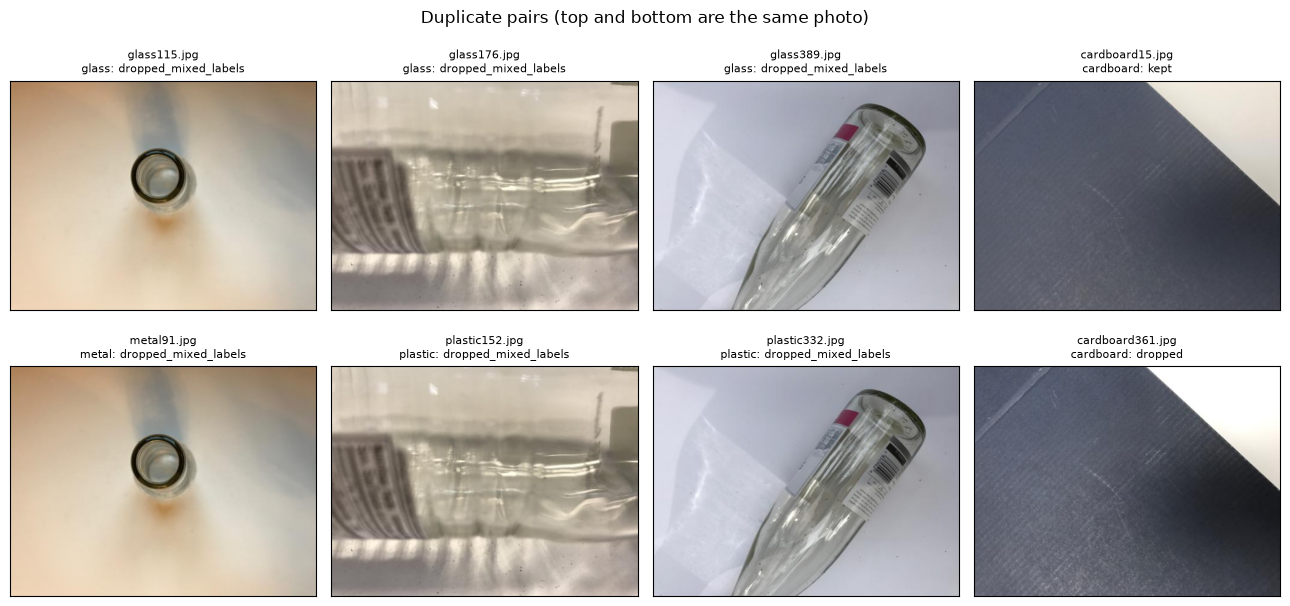

In [5]:
dups = pd.read_csv(REPORTS / "duplicates.csv")
display(pd.crosstab(dups["label"], dups["action"], margins=True))

# 4 example pairs, label conflicts first
groups = sorted(dups.groupby("group"), key=lambda g: (g[1]["label"].nunique() == 1, g[0]))[:4]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for col, (_, g) in enumerate(groups):
    for row, (_, r) in enumerate(g.iterrows()):
        show(axes[row, col], ROOT / r["path"], f"{Path(r['path']).name}\n{r['label']}: {r['action']}")
fig.suptitle("Duplicate pairs (top and bottom are the same photo)")
fig.tight_layout()
fig.savefig(REPORTS / "data_duplicates.png", dpi=100)
plt.show()